# Linear Models: Regression and Exceedance Probability (10 km folds, no subbasin)

**Objective:** Fit linear models (OLS, Ridge, Lasso) to predict log nitrate, and logistic regression (no penalty, L2, L1) to predict the probability of exceeding 10 mg/L. This version is the **baseline without location features**: it uses the 50 selected features from `load_model_data()` (including elevation, without subbasin) and the original 10 km spatial folds (folds 0–3; fold 4 is the untouched holdout).

Companion notebooks with subbasin features: `linear_models10km_subbasins.ipynb` and `linear_models5km_subbasins.ipynb`.

In [1]:
import sys
from pathlib import Path

# Set root
cwd = Path.cwd()
ROOT = next(p for p in [cwd, *cwd.parents] if (p / ".git").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from src.features.preprocessing import load_model_data
from src.evaluation import splits, leakage
from src.evaluation.make_splits import load_split, SPLITS
from src.evaluation.results_log import save_run, load_runs, summarize

In [2]:
# ===== Settings: change these, then Restart & Run All =====
SPLIT = "10km"             # "10km", "10km_subbasin", "7.5km_subbasin", "5km_subbasin"
USE_SUBBASIN = False       # add one 0/1 column per subbasin
DROP_ELEVATION = False     # True: remove elevation_m
THRESHOLD_MG_L = 10

In [3]:
# Load the cleaned/merged dataset
X, y, meta = load_model_data(subbasin=USE_SUBBASIN, drop_elevation=DROP_ELEVATION)
FEATURES = list(X.columns)

data = load_split(pd.concat([meta, X], axis=1).assign(log_nitrate=y), split=SPLIT)
print(f"split={SPLIT} | subbasin={USE_SUBBASIN} | drop elevation={DROP_ELEVATION} | {len(FEATURES)} features")
print(data["fold"].value_counts().sort_index().to_dict(), "| holdout rows:", int(data["holdout"].sum()))

split=10km | subbasin=False | drop elevation=False | 50 features
{0: 1035, 1: 972, 2: 1143, 3: 1041, 4: 1089} | holdout rows: 1089


In [4]:
# Set the training folds and the holdout

train_val = data[~data["holdout"]].reset_index(drop=True)       # Training set with 4 folds


X_tv = train_val[FEATURES]
y_tv = train_val["log_nitrate"]

# Print the sizes of the training folds
print(train_val["fold"].value_counts().sort_index().to_dict())

{0: 1035, 1: 972, 2: 1143, 3: 1041}


## 0. Baseline (Dummy)

**Objective:** Predict the training mean of log nitrate for every sample. Every model below should beat this reference.

In [5]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error

In [6]:
from sklearn.metrics import r2_score

def make_model():
    """Replace with your model. A new, untrained model is created for every fold."""
    return DummyRegressor(strategy="mean")        # baseline: always predicts the training mean

oof_pred = np.full(len(train_val), np.nan)        # out-of-fold prediction for every row
fold_scores = []

for train, test in splits.iter_folds(train_val["fold"]):
    model = make_model()
    model.fit(X_tv[train], y_tv[train])
    oof_pred[test] = model.predict(X_tv[test])

    fold = int(train_val.loc[test, "fold"].iloc[0])
    fold_scores.append({"fold": fold,
                        "rmse_log": root_mean_squared_error(y_tv[test], oof_pred[test]),
                        "r2": r2_score(y_tv[test], oof_pred[test])})

fold_scores = pd.DataFrame(fold_scores)
print(fold_scores.round(3).to_string(index=False))
print(f"Overall RMSE (log): {root_mean_squared_error(y_tv, oof_pred):.3f}")

dummy_reg_scores = fold_scores
save_run(dummy_reg_scores, model="Dummy (mean)", task="regression", author="Andrea",
         split=SPLIT, use_subbasin=USE_SUBBASIN, drop_elevation=DROP_ELEVATION,
         n_features=len(FEATURES));

 fold  rmse_log     r2
    0     1.227 -0.007
    1     1.183 -0.000
    2     1.222 -0.006
    3     1.314 -0.028
Overall RMSE (log): 1.238
Saved 4 folds to results\model_runs\andrea__dummy-mean__regression__10km__subbasin0__noelev0.csv


## 1. Linear Regression (OLS)

**Objective:** Fit an ordinary least squares model on log nitrate as the simplest linear reference. Features are median-imputed and standardized inside a pipeline fitted on each training fold. Because drainage groups and hydrologic groups each sum to 100%, one class from each set (moderate drainage, hydrologic group B) is dropped as the reference category to avoid perfect collinearity.

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut
from sklearn.metrics import r2_score

EMPTY_COLS = [c for c in FEATURES if data[c].nunique() <= 1]   # subbasins with no samples
REFERENCE_COLS = ["soil_drainage_moderate_pct", "soil_hydgrpdcd_pct_b", "subbasin_FOREBAY AQUIFER"]
LINEAR_FEATURES = [f for f in FEATURES if f not in REFERENCE_COLS + EMPTY_COLS]
print(f"{len(LINEAR_FEATURES)} linear features | dropped as empty: {EMPTY_COLS}")


def evaluate_regression(make_model, features):
    """Fit a new model on each training fold and score it on the held-out fold.
    If the model is a GridSearchCV, alpha is tuned only on that fold's training folds."""
    oof = np.full(len(train_val), np.nan)
    scores = []
    for train, test in splits.iter_folds(train_val["fold"]):
        model = make_model()
        fit_kwargs = {"groups": train_val.loc[train, "fold"]} if isinstance(model, GridSearchCV) else {}
        model.fit(X_tv.loc[train, features], y_tv[train], **fit_kwargs)
        oof[test] = model.predict(X_tv.loc[test, features])
        row = {"fold": int(train_val.loc[test, "fold"].iloc[0]),
               "rmse_log": root_mean_squared_error(y_tv[test], oof[test]),
               "r2": r2_score(y_tv[test], oof[test])}
        if isinstance(model, GridSearchCV):
            row.update(model.best_params_)
        scores.append(row)
    return pd.DataFrame(scores), oof


def make_linear():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression())


ols_scores, ols_oof = evaluate_regression(make_linear, LINEAR_FEATURES)
print(ols_scores.round(3).to_string(index=False))
print(f"Overall RMSE (log): {root_mean_squared_error(y_tv, ols_oof):.3f} | "
      f"Overall R²: {r2_score(y_tv, ols_oof):.3f}")

48 linear features | dropped as empty: []
 fold  rmse_log     r2
    0     1.097  0.195
    1     1.343 -0.289
    2     1.154  0.102
    3     1.121  0.252
Overall RMSE (log): 1.179 | Overall R²: 0.088


In [8]:
save_run(ols_scores, model="Linear regression", task="regression", author="Andrea",
         split=SPLIT, use_subbasin=USE_SUBBASIN, drop_elevation=DROP_ELEVATION,
         n_features=len(LINEAR_FEATURES));

Saved 4 folds to results\model_runs\andrea__linear-regression__regression__10km__subbasin0__noelev0.csv


 ## 2. Ridge and Lasso

**Objective:** Penalize large coefficients to make the linear model more stable in areas it has not seen. The penalty `alpha` is chosen by nested cross-validation: within each outer training set, each of the three remaining spatial folds is held out in turn (leave-one-fold-out) to select `alpha`, so the outer test fold is never used for tuning.

In [9]:
RIDGE_ALPHAS = np.logspace(0, 6, 13)   # 1 to 1,000,000


def make_ridge():
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge())
    return GridSearchCV(pipe, {"ridge__alpha": RIDGE_ALPHAS}, cv=LeaveOneGroupOut(),
                        scoring="neg_root_mean_squared_error")


ridge_scores, ridge_oof = evaluate_regression(make_ridge, LINEAR_FEATURES)
print(ridge_scores.round(3).to_string(index=False))
print(f"Overall RMSE (log): {root_mean_squared_error(y_tv, ridge_oof):.3f} | "
      f"Overall R²: {r2_score(y_tv, ridge_oof):.3f}")

 fold  rmse_log     r2  ridge__alpha
    0     1.080  0.220      3162.278
    1     1.237 -0.094      3162.278
    2     1.135  0.132      3162.278
    3     1.115  0.260     10000.000
Overall RMSE (log): 1.141 | Overall R²: 0.145


In [10]:
save_run(ridge_scores, model="Ridge", task="regression", author="Andrea",
         split=SPLIT, use_subbasin=USE_SUBBASIN, drop_elevation=DROP_ELEVATION,
         n_features=len(LINEAR_FEATURES));

Saved 4 folds to results\model_runs\andrea__ridge__regression__10km__subbasin0__noelev0.csv


In [11]:
LASSO_ALPHAS = [0.001, 0.003, 0.01, 0.03, 0.1, 0.2, 0.3, 0.5]


def make_lasso():
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Lasso(max_iter=20_000))
    return GridSearchCV(pipe, {"lasso__alpha": LASSO_ALPHAS}, cv=LeaveOneGroupOut(),
                        scoring="neg_root_mean_squared_error")


lasso_scores, lasso_oof = evaluate_regression(make_lasso, LINEAR_FEATURES)
print(lasso_scores.round(3).to_string(index=False))
print(f"Overall RMSE (log): {root_mean_squared_error(y_tv, lasso_oof):.3f} | "
      f"Overall R²: {r2_score(y_tv, lasso_oof):.3f}")

 fold  rmse_log     r2  lasso__alpha
    0     1.094  0.199          0.10
    1     1.256 -0.127          0.03
    2     1.137  0.129          0.10
    3     1.095  0.286          0.10
Overall RMSE (log): 1.145 | Overall R²: 0.140


In [12]:
save_run(lasso_scores, model="Lasso", task="regression", author="Andrea",
         split=SPLIT, use_subbasin=USE_SUBBASIN, drop_elevation=DROP_ELEVATION,
         n_features=len(LINEAR_FEATURES));

Saved 4 folds to results\model_runs\andrea__lasso__regression__10km__subbasin0__noelev0.csv


## 3. Probability of Exceeding 10 mg/L (Logistic Regression)

**Objective:** Predict the probability that a sample exceeds the 10 mg/L drinking-water limit. Logistic regression is the classification counterpart of the linear models above: no penalty (counterpart of OLS), L2 (Ridge) and L1 (Lasso). The regularization strength `C` (the inverse of `alpha`; smaller `C` means a stronger penalty) is chosen by nested cross-validation, minimizing the Brier score. Models are evaluated with AUC (how well they rank exceeding vs. non-exceeding samples) and Brier skill score (improvement in probability error over always predicting the training exceedance rate).

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss

exceeds_tv = (np.expm1(y_tv) > 10).to_numpy()


def evaluate_classification(make_model, features):
    """Fit a new classifier on each training fold and score its probabilities on the held-out fold."""
    oof = np.full(len(train_val), np.nan)
    scores = []
    for train, test in splits.iter_folds(train_val["fold"]):
        model = make_model()
        fit_kwargs = {"groups": train_val.loc[train, "fold"]} if isinstance(model, GridSearchCV) else {}
        model.fit(X_tv.loc[train, features], exceeds_tv[train], **fit_kwargs)
        oof[test] = model.predict_proba(X_tv.loc[test, features])[:, 1]
        baseline = brier_score_loss(exceeds_tv[test], np.full(test.sum(), exceeds_tv[train].mean()))
        row = {"fold": int(train_val.loc[test, "fold"].iloc[0]),
               "auc": roc_auc_score(exceeds_tv[test], oof[test]),
               "brier_skill": 1 - brier_score_loss(exceeds_tv[test], oof[test]) / baseline}
        if isinstance(model, GridSearchCV):
            row.update(model.best_params_)
        scores.append(row)
    return pd.DataFrame(scores), oof


def summarize_classification(scores, oof):
    print(scores.round(3).to_string(index=False))
    print(f"Mean AUC: {scores['auc'].mean():.3f} | Mean Brier skill: {scores['brier_skill'].mean():.3f}")


dummy_clf_scores, dummy_clf_oof = evaluate_classification(
    lambda: DummyClassifier(strategy="prior"), LINEAR_FEATURES)
summarize_classification(dummy_clf_scores, dummy_clf_oof)

save_run(dummy_clf_scores, model="Dummy (prior)", task="classification", author="Andrea",
         split=SPLIT, use_subbasin=USE_SUBBASIN, drop_elevation=DROP_ELEVATION,
         n_features=len(LINEAR_FEATURES));

 fold  auc  brier_skill
    0  0.5          0.0
    1  0.5          0.0
    2  0.5          0.0
    3  0.5          0.0
Mean AUC: 0.500 | Mean Brier skill: 0.000
Saved 4 folds to results\model_runs\andrea__dummy-prior__classification__10km__subbasin0__noelev0.csv


In [14]:
C_VALUES = np.logspace(-4, 2, 13)   # 0.0001 to 100


def make_logistic_plain():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(C=np.inf, max_iter=5000))


def make_logistic(l1_ratio):
    """l1_ratio=0 -> L2 (Ridge-like), l1_ratio=1 -> L1 (Lasso-like)."""
    solver = "saga" if l1_ratio == 1 else "lbfgs"
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(l1_ratio=l1_ratio, solver=solver, max_iter=5000))
    return GridSearchCV(pipe, {"logisticregression__C": C_VALUES}, cv=LeaveOneGroupOut(),
                        scoring="neg_brier_score")


print("No penalty")
logit_scores, logit_oof = evaluate_classification(make_logistic_plain, LINEAR_FEATURES)
summarize_classification(logit_scores, logit_oof)

print("\nL2 (Ridge)")
logit_l2_scores, logit_l2_oof = evaluate_classification(lambda: make_logistic(0), LINEAR_FEATURES)
summarize_classification(logit_l2_scores, logit_l2_oof)

print("\nL1 (Lasso)")
logit_l1_scores, logit_l1_oof = evaluate_classification(lambda: make_logistic(1), LINEAR_FEATURES)
summarize_classification(logit_l1_scores, logit_l1_oof)

No penalty
 fold   auc  brier_skill
    0 0.755        0.155
    1 0.651       -0.140
    2 0.756        0.186
    3 0.776        0.165
Mean AUC: 0.735 | Mean Brier skill: 0.091

L2 (Ridge)
 fold   auc  brier_skill  logisticregression__C
    0 0.781        0.194                  0.003
    1 0.624       -0.069                  0.003
    2 0.747        0.178                  0.001
    3 0.799        0.235                  0.001
Mean AUC: 0.738 | Mean Brier skill: 0.135

L1 (Lasso)
 fold   auc  brier_skill  logisticregression__C
    0 0.775        0.174                  0.010
    1 0.629       -0.085                  0.032
    2 0.748        0.176                  0.010
    3 0.793        0.230                  0.010
Mean AUC: 0.736 | Mean Brier skill: 0.124


In [15]:
save_run(logit_scores, model="Logistic (no penalty)", task="classification", author="Andrea",
         split=SPLIT, use_subbasin=USE_SUBBASIN, drop_elevation=DROP_ELEVATION,
         n_features=len(LINEAR_FEATURES));

save_run(logit_l1_scores, model="Logistic L1", task="classification", author="Andrea",
         split=SPLIT, use_subbasin=USE_SUBBASIN, drop_elevation=DROP_ELEVATION,
         n_features=len(LINEAR_FEATURES));

save_run(logit_l2_scores, model="Logistic L2", task="classification", author="Andrea",
         split=SPLIT, use_subbasin=USE_SUBBASIN, drop_elevation=DROP_ELEVATION,
         n_features=len(LINEAR_FEATURES));

Saved 4 folds to results\model_runs\andrea__logistic-no-penalty__classification__10km__subbasin0__noelev0.csv
Saved 4 folds to results\model_runs\andrea__logistic-l1__classification__10km__subbasin0__noelev0.csv
Saved 4 folds to results\model_runs\andrea__logistic-l2__classification__10km__subbasin0__noelev0.csv


### Risk levels (L2 logistic, out-of-fold)

Group the predicted probabilities into Low (< 25%), Moderate (25–50%) and High (> 50%), and check how often samples in each level actually exceeded 10 mg/L.

In [16]:
risk_level = pd.cut(logit_l2_oof, [0, 0.25, 0.5, 1.0001], right=False,
                    labels=["Low (<25%)", "Moderate (25-50%)", "High (>50%)"])

risk_summary = (pd.DataFrame({"risk_level": risk_level, "exceeds": exceeds_tv})
                .groupby("risk_level", observed=False)["exceeds"]
                .agg(samples="size", observed_exceedance_rate="mean"))
risk_summary.round(3)

,samples,observed_exceedance_rate
risk_level,,
Low (<25%),1350,0.053
Moderate (25-50%),1933,0.445
High (>50%),908,0.534


## 4. Results Summary

Mean ± standard deviation across the four spatial folds, the same summary used for the team comparison.

In [17]:
def mean_sd(scores, metrics):
    return {m: f"{scores[m].mean():.3f} ± {scores[m].std():.3f}" for m in metrics}


regression_results = pd.DataFrame([
    {"model": name, **mean_sd(scores, ["rmse_log", "r2"])}
    for name, scores in {"Dummy (mean)": dummy_reg_scores, "Linear regression": ols_scores,
                         "Ridge": ridge_scores, "Lasso": lasso_scores}.items()
])

classification_results = pd.DataFrame([
    {"model": name, **mean_sd(scores, ["auc", "brier_skill"])}
    for name, scores in {"Dummy (prior)": dummy_clf_scores, "Logistic (no penalty)": logit_scores,
                         "Logistic L2": logit_l2_scores, "Logistic L1": logit_l1_scores}.items()
])

display(regression_results)
display(classification_results)

,model,rmse_log,r2
0,Dummy (mean),1.236 ± 0.055,-0.010 ± 0.012
1,Linear regression,1.179 ± 0.112,0.065 ± 0.244
2,Ridge,1.142 ± 0.068,0.129 ± 0.159
3,Lasso,1.146 ± 0.076,0.122 ± 0.178


,model,auc,brier_skill
0,Dummy (prior),0.500 ± 0.000,0.000 ± 0.000
1,Logistic (no penalty),0.735 ± 0.057,0.091 ± 0.155
2,Logistic L2,0.738 ± 0.079,0.135 ± 0.138
3,Logistic L1,0.736 ± 0.074,0.124 ± 0.141


All saved runs from the team (`results/model_runs/`), for comparison across models and configurations:

In [18]:
summarize(load_runs(), task="regression")

rmse_log  \
                                                                                         mean   
task       model                 author   split          use_subbasin drop_elevation            
regression Dummy (mean)          Andrea   10km           False        False             1.236   
           Lasso                 Andrea   10km           False        False             1.146   
                                          10km_subbasin  True         True              1.016   
                                          5km_subbasin   True         True              1.031   
           Linear regression     Andrea   10km           False        False             1.179   
           RandomForestRegressor Charlsey 10km           False        False             1.074   
                                          10km_subbasin  True         True              0.972   
                                          5km_subbasin   True         True              0.986   
                                          7.5km_subbasin True         True              0.998   
           Ridge                 Andrea   10km           False        False             1.142   
                                          10km_subbasin  True         True              1.031   
                                          5km_subbasin   True         True              1.033   
           XGBoost BRT           Karuna   10km           False        False             1.071   
                                                         True         True              1.047   
                                          10km_subbasin  True         True              0.989   
                                          5km_subbasin   True         True              1.006   
                                          7.5km_subbasin True         True              1.026   

                                                                                             \
                                                                                        std   
task       model                 author   split          use_subbasin drop_elevation          
regression Dummy (mean)          Andrea   10km           False        False           0.055   
           Lasso                 Andrea   10km           False        False           0.076   
                                          10km_subbasin  True         True            0.081   
                                          5km_subbasin   True         True            0.012   
           Linear regression     Andrea   10km           False        False           0.112   
           RandomForestRegressor Charlsey 10km           False        False           0.044   
                                          10km_subbasin  True         True            0.062   
                                          5km_subbasin   True         True            0.033   
                                          7.5km_subbasin True         True            0.068   
           Ridge                 Andrea   10km           False        False           0.068   
                                          10km_subbasin  True         True            0.068   
                                          5km_subbasin   True         True            0.010   
           XGBoost BRT           Karuna   10km           False        False           0.030   
                                                         True         True            0.021   
                                          10km_subbasin  True         True            0.071   
                                          5km_subbasin   True         True            0.027   
                                          7.5km_subbasin True         True            0.040   

                                                                                         r2  \
                                                                                       mean   
task       model                 author   split      

In [19]:
summarize(load_runs(), task="classification")

auc  \
                                                                                            mean   
task           model                  author   split          use_subbasin drop_elevation          
classification Dummy (prior)          Andrea   10km           False        False           0.500   
               Logistic (no penalty)  Andrea   10km           False        False           0.735   
               Logistic L1            Andrea   10km           False        False           0.736   
                                               10km_subbasin  True         True            0.799   
                                               5km_subbasin   True         True            0.796   
               Logistic L2            Andrea   10km           False        False           0.738   
                                               10km_subbasin  True         True            0.791   
                                               5km_subbasin   True         True            0.792   
               RandomForestClassifier Charlsey 10km           False        False           0.790   
                                               10km_subbasin  True         True            0.823   
                                               5km_subbasin   True         True            0.819   
                                               7.5km_subbasin True         True            0.794   
               XGBoost BRT classifier Karuna   10km           False        False           0.785   
                                                              True         True            0.800   
                                               10km_subbasin  True         True            0.814   
                                               5km_subbasin   True         True            0.816   
                                               7.5km_subbasin True         True            0.788   

                                                                                                  \
                                                                                             std   
task           model                  author   split          use_subbasin drop_elevation          
classification Dummy (prior)          Andrea   10km           False        False           0.000   
               Logistic (no penalty)  Andrea   10km           False        False           0.057   
               Logistic L1            Andrea   10km           False        False           0.074   
                                               10km_subbasin  True         True            0.035   
                                               5km_subbasin   True         True            0.023   
               Logistic L2            Andrea   10km           False        False           0.079   
                                               10km_subbasin  True         True            0.031   
                                               5km_subbasin   True         True            0.025   
               RandomForestClassifier Charlsey 10km           False        False           0.033   
                                               10km_subbasin  True         True            0.033   
                                               5km_subbasin   True         True            0.022   
                                               7.5km_subbasin True         True            0.035   
               XGBoost BRT classifier Karuna   10km           False        False           0.055   
                                                              True         True            0.039   
                                               10km_subbasin  True         True            0.031   
                                               5km_subbasin   True         True            0.038   
                                               7.5km_subbasin True         True            0.020   

                                                                                          b

## 5. Diagnostic Plots

**Objective:** Visualize out-of-fold predictions (each point predicted by a model that did not see it during training) for the best regression model (Ridge) and the best classification model (L2 logistic regression).

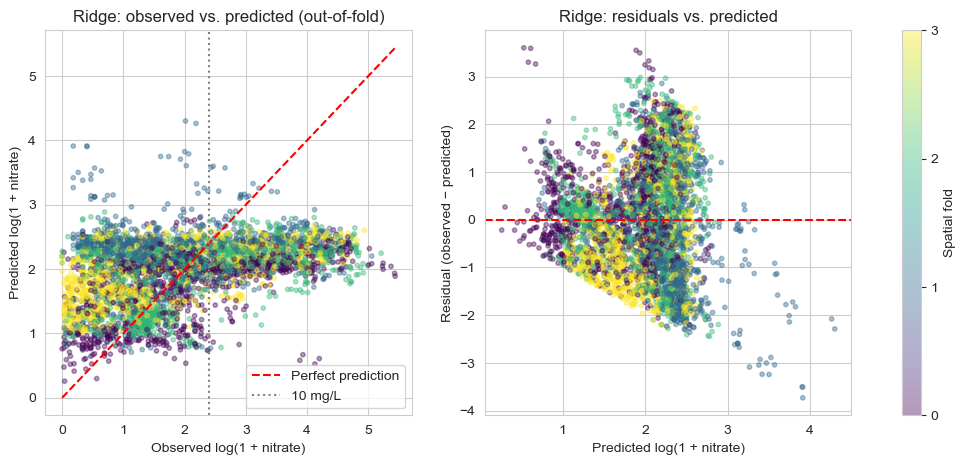

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

fold_colors = train_val["fold"].astype(int)
residuals = y_tv - ridge_oof

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
sc = axs[0].scatter(y_tv, ridge_oof, c=fold_colors, cmap="viridis", alpha=0.4, s=10)
lims = [0, y_tv.max()]
axs[0].plot(lims, lims, "r--", label="Perfect prediction")
axs[0].axvline(np.log1p(10), color="gray", linestyle=":", label="10 mg/L")
axs[0].set_xlabel("Observed log(1 + nitrate)")
axs[0].set_ylabel("Predicted log(1 + nitrate)")
axs[0].set_title("Ridge: observed vs. predicted (out-of-fold)")
axs[0].legend()

axs[1].scatter(ridge_oof, residuals, c=fold_colors, cmap="viridis", alpha=0.4, s=10)
axs[1].axhline(0, color="r", linestyle="--")
axs[1].set_xlabel("Predicted log(1 + nitrate)")
axs[1].set_ylabel("Residual (observed − predicted)")
axs[1].set_title("Ridge: residuals vs. predicted")
fig.colorbar(sc, ax=axs, label="Spatial fold", ticks=[0, 1, 2, 3])
plt.show()

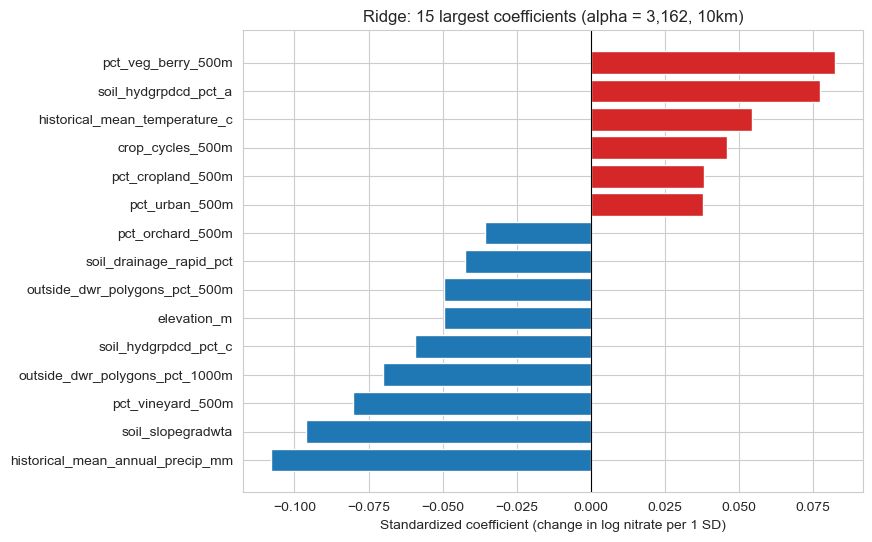

In [21]:
best_alpha = ridge_scores["ridge__alpha"].median()

final_ridge = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=best_alpha))
final_ridge.fit(X_tv[LINEAR_FEATURES], y_tv)

coefs = pd.Series(final_ridge[-1].coef_, index=LINEAR_FEATURES)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index[:15]).sort_values()

plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=np.where(top.values > 0, "tab:red", "tab:blue"))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Standardized coefficient (change in log nitrate per 1 SD)")
plt.title(f"Ridge: 15 largest coefficients (alpha = {best_alpha:,.0f}, {SPLIT})")
plt.show()

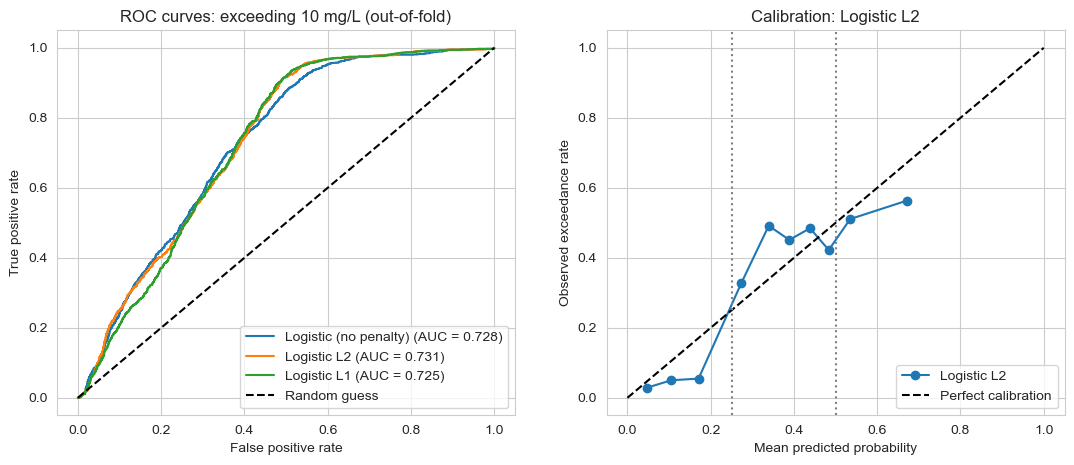

In [22]:
from sklearn.metrics import roc_curve
from sklearn.calibration import calibration_curve

fig, axs = plt.subplots(1, 2, figsize=(13, 5))

for name, p in {"Logistic (no penalty)": logit_oof,
                "Logistic L2": logit_l2_oof,
                "Logistic L1": logit_l1_oof}.items():
    fpr, tpr, _ = roc_curve(exceeds_tv, p)
    axs[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(exceeds_tv, p):.3f})")
axs[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axs[0].set_xlabel("False positive rate")
axs[0].set_ylabel("True positive rate")
axs[0].set_title("ROC curves: exceeding 10 mg/L (out-of-fold)")
axs[0].legend()

prob_true, prob_pred = calibration_curve(exceeds_tv, logit_l2_oof, n_bins=10, strategy="quantile")
axs[1].plot(prob_pred, prob_true, "o-", label="Logistic L2")
axs[1].plot([0, 1], [0, 1], "k--", label="Perfect calibration")
for cut in [0.25, 0.5]:
    axs[1].axvline(cut, color="gray", linestyle=":")
axs[1].set_xlabel("Mean predicted probability")
axs[1].set_ylabel("Observed exceedance rate")
axs[1].set_title("Calibration: Logistic L2")
axs[1].legend()
plt.show()

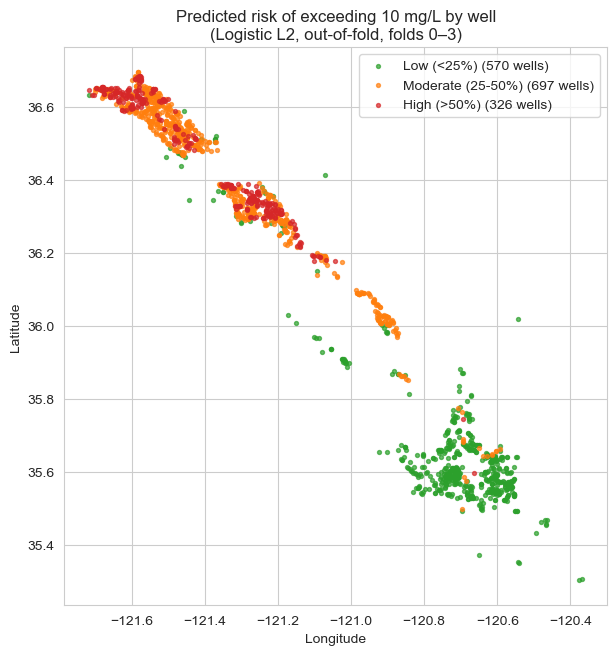

In [23]:
well_risk = (train_val.assign(prob=logit_l2_oof)
             .groupby("gm_well_id")
             .agg(lat=("gm_latitude", "first"), lon=("gm_longitude", "first"), prob=("prob", "mean")))
well_risk["risk_level"] = pd.cut(well_risk["prob"], [0, 0.25, 0.5, 1.0001], right=False,
                                 labels=["Low (<25%)", "Moderate (25-50%)", "High (>50%)"])

colors = {"Low (<25%)": "tab:green", "Moderate (25-50%)": "tab:orange", "High (>50%)": "tab:red"}
plt.figure(figsize=(7, 8))
for level, color in colors.items():
    sub = well_risk[well_risk["risk_level"] == level]
    plt.scatter(sub["lon"], sub["lat"], s=8, color=color, alpha=0.7, label=f"{level} ({len(sub)} wells)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Predicted risk of exceeding 10 mg/L by well\n(Logistic L2, out-of-fold, folds 0–3)")
plt.legend()
plt.gca().set_aspect("equal")
plt.show()

## 6. Conclusions

**Regression (log nitrate)**
- Ridge performed best (RMSE 1.142 ± 0.068 vs. 1.236 ± 0.055 for the dummy baseline, about 8% lower; R² = 0.129 ± 0.159), with Lasso close behind (RMSE 1.146 ± 0.076).
- Unpenalized linear regression was unstable in unseen areas: in fold 1 it predicted worse than the mean (R² = −0.28). Regularization reduced this (Ridge R² = −0.09 in fold 1).
- The selected Ridge penalties were large (alpha = 3,162–10,000), reflecting strong collinearity among agricultural, terrain, and climate predictors.

**Probability of exceeding 10 mg/L**
- The three logistic models performed similarly (mean AUC ≈ 0.74). L2 had the best probability accuracy (Brier skill = 0.135 ± 0.138), followed by L1 (0.124) and no penalty (0.091).
- Fold 1 was again the weakest (AUC ≈ 0.62–0.65, negative Brier skill), indicating a region where linear models do not transfer well.

**Risk levels (L2 logistic, out-of-fold)**
- *Low* (< 25%) is reliable: 5.3% of these 1,350 samples exceeded 10 mg/L.
- *Moderate* (25–50%) and *High* (> 50%) are poorly separated (44.5% vs. 53.4% observed exceedance): linear models identify low-risk areas well but cannot distinguish among higher-risk areas.

**Diagnostics**
- Out-of-fold predictions are compressed toward the mean (predicted log nitrate ≈ 1–2.6 vs. observed 0–5.4): the model overestimates low-nitrate wells and underestimates the most contaminated ones.
- Predicted probabilities are well calibrated below ~25% but flatten at ~45–55% observed exceedance above ~30%, which explains why Moderate and High are poorly separated. Predicted risk follows a north–south gradient, with higher risk in the northern (lower) Salinas Valley.

**Comparison with subbasin features**
- Adding subbasin and dropping elevation (`linear_models10km_subbasins.ipynb`) improves the linear models substantially (Lasso RMSE 1.016, R² ≈ 0.28; logistic L1 AUC ≈ 0.80). Most of this gain reflects location (which aquifer a well is over) rather than additional land-use information, so this notebook is the reference for what the landscape features alone can predict.

**Caveats:** results use folds 0–3 only; the fold 4 holdout has not been used. Errors are on the log scale. Coefficients and associations are not causal effects.

Save this last file for the final evaluation (when we have compared all of our models and have chosen a final one).

In [24]:
# ============================================================
# FINAL EVALUATION ON THE HOLD-OUT FOLD
# Run this ONCE, for the final chosen model only, after all
# model choices (features, hyperparameters) are finished.
# ============================================================
RUN_FINAL_EVALUATION = False

if RUN_FINAL_EVALUATION:
    holdout_df = data[data["holdout"]].reset_index(drop=True)
    final_model = make_model()
    final_model.fit(X_tv, y_tv)                                 # all four development folds
    holdout_pred = final_model.predict(holdout_df[FEATURES])
    y_ho = holdout_df["log_nitrate"]
    print(f"Hold-out ({SPLIT}) RMSE (log): {root_mean_squared_error(y_ho, holdout_pred):.3f} "
          f"| R²: {r2_score(y_ho, holdout_pred):.3f} "
          f"| AUC: {roc_auc_score(np.expm1(y_ho) > THRESHOLD_MG_L, holdout_pred):.3f}")
